### Set up the notebook

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Load validated dataset
df = pd.read_csv(r"Emigraion_Cleaned.csv")

# Define complete historical years
years = [str(year) for year in range(2014, 2026)]

# Calculate district totals for 2014–2025
df['Historical_Total'] = df[years].sum(axis=1)

# Display dataset information
print("Dataset Shape:", df.shape)
print("Historical Period: 2014–2025")

df.head()

Dataset Shape: (154, 16)
Historical Period: 2014–2025


,Districts,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,Total,Historical_Total
0,Islamabad,8943,9028,8472,4635,2471,4299,1824,2693,6554,10359,8630,8104,5005,81017,76012
1,Attock,8813,10742,9716,8333,6844,8021,3516,4498,12328,16761,14852,13778,7583,125785,118202
2,Bahwalnagar,5403,7259,11371,6340,4316,6600,2163,2479,8093,7362,6050,6252,3999,77687,73688
3,Bahwalpur,6292,8760,10289,6455,4311,7787,2786,3294,11463,11267,7920,7548,5363,93535,88172
4,Bhakar,3844,3566,3381,1646,1499,1410,341,516,1429,1733,1745,1778,1186,24074,22888


### Descriptive statistics

In [4]:
# Descriptive statistics for historical district totals

descriptive_stats = df['Historical_Total'].describe()

print("Descriptive Statistics (2014–2025)")
print(descriptive_stats)

# Additional statistical measures
print("\nAdditional Measures")

print("Skewness:", df['Historical_Total'].skew())
print("Kurtosis:", df['Historical_Total'].kurt())

Descriptive Statistics (2014–2025)
count       154.000000
mean      50282.357143
std       63719.820545
min          37.000000
25%        2654.000000
50%       27343.500000
75%       73545.000000
max      324939.000000
Name: Historical_Total, dtype: float64

Additional Measures
Skewness: 1.918255543390141
Kurtosis: 3.9249741736601056


### Summary Table

In [5]:
summary = pd.DataFrame({
    'Measure': [
        'Mean',
        'Median',
        'Standard Deviation',
        'Variance',
        'Minimum',
        'Maximum',
        'Range',
        'Skewness',
        'Kurtosis'
    ],
    'Value': [
        df['Historical_Total'].mean(),
        df['Historical_Total'].median(),
        df['Historical_Total'].std(),
        df['Historical_Total'].var(),
        df['Historical_Total'].min(),
        df['Historical_Total'].max(),
        df['Historical_Total'].max() - df['Historical_Total'].min(),
        df['Historical_Total'].skew(),
        df['Historical_Total'].kurt()
    ]
})

summary

,Measure,Value
0,Mean,5.028236e+04
1,Median,2.734350e+04
2,Standard Deviation,6.371982e+04
3,Variance,4.060216e+09
4,Minimum,3.700000e+01
5,Maximum,3.249390e+05
6,Range,3.249020e+05
7,Skewness,1.918256e+00
8,Kurtosis,3.924974e+00


### Trend for Gilgit over Time

In [6]:
gilgit = df[df['Districts'].str.strip().str.lower() == 'gilgit']

gilgit_trend = gilgit[years].T.reset_index()

gilgit_trend.columns = ['Year', 'Emigrants']

gilgit_trend['Year'] = gilgit_trend['Year'].astype(int)

gilgit_trend

,Year,Emigrants
0,2014,1660
1,2015,2325
2,2016,2093
3,2017,1924
4,2018,1941
5,2019,1392
6,2020,115
7,2021,311
8,2022,464
9,2023,560


### Visualization

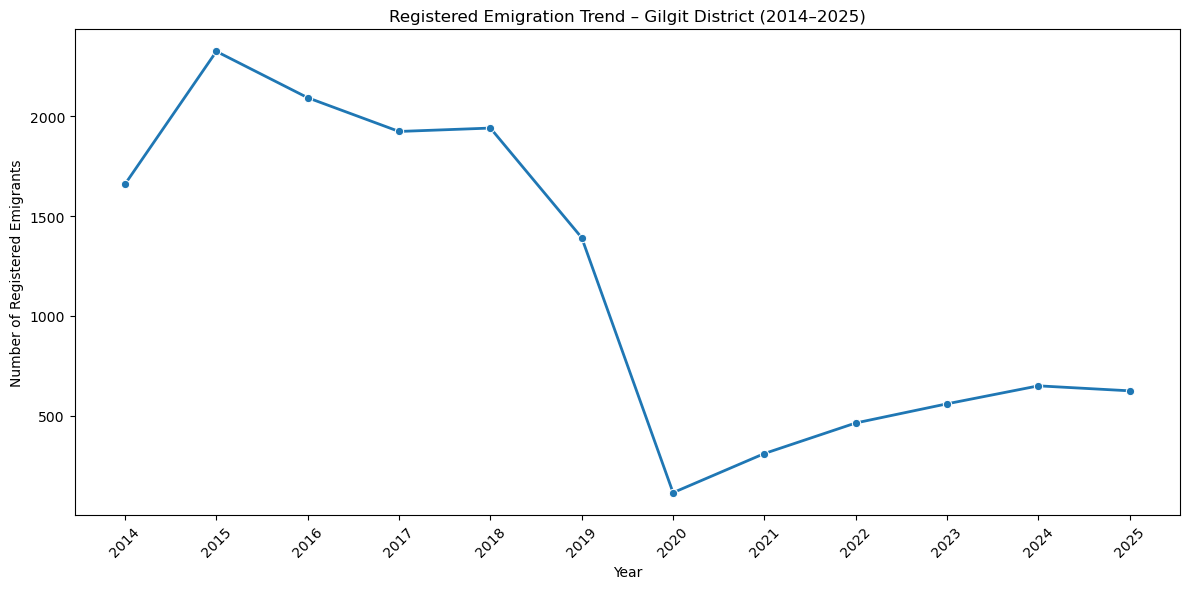

In [7]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=gilgit_trend,
    x='Year',
    y='Emigrants',
    marker='o',
    linewidth=2
)

plt.title('Registered Emigration Trend – Gilgit District (2014–2025)')
plt.xlabel('Year')
plt.ylabel('Number of Registered Emigrants')
plt.xticks(gilgit_trend['Year'], rotation=45)

plt.tight_layout()
plt.show()

### Calculate district-level variability

In [8]:
# Calculate district-level mean and standard deviation

district_variability = pd.DataFrame({
    'Districts': df['Districts'],
    'Mean_Emigration': df[years].mean(axis=1),
    'Std_Deviation': df[years].std(axis=1),
    'Variance': df[years].var(axis=1)
})

district_variability.head()

,Districts,Mean_Emigration,Std_Deviation,Variance
0,Islamabad,6334.333333,2997.524383,8.985152e+06
1,Attock,9850.166667,4041.676156,1.633515e+07
2,Bahwalnagar,6140.666667,2473.217424,6.116804e+06
3,Bahwalpur,7347.666667,2890.071227,8.352512e+06
4,Bhakar,1907.333333,1121.986901,1.258855e+06


### Calculate coefficient of variation

In [9]:
district_variability['CV_Percent'] = (
    district_variability['Std_Deviation'] /
    district_variability['Mean_Emigration']
) * 100

district_variability.head()

,Districts,Mean_Emigration,Std_Deviation,Variance,CV_Percent
0,Islamabad,6334.333333,2997.524383,8.985152e+06,47.321860
1,Attock,9850.166667,4041.676156,1.633515e+07,41.031551
2,Bahwalnagar,6140.666667,2473.217424,6.116804e+06,40.276041
3,Bahwalpur,7347.666667,2890.071227,8.352512e+06,39.333184
4,Bhakar,1907.333333,1121.986901,1.258855e+06,58.824899


### Identify the most volatile districts

In [10]:
# Top 10 districts with highest relative variability

most_volatile = district_variability.sort_values(
    by='CV_Percent',
    ascending=False
).head(10)

most_volatile

,Districts,Mean_Emigration,Std_Deviation,Variance,CV_Percent
121,Lehri,3.083333,9.462446,8.953788e+01,306.890131
153,Skardu,7.916667,18.841243,3.549924e+02,237.994644
60,Sujawal,135.166667,243.099618,5.909742e+04,179.851752
147,Astore,91.500000,162.728720,2.648064e+04,177.845596
133,Turbat,16.250000,23.875149,5.700227e+02,146.923992
44,Karachi (Central),15536.750000,20868.789115,4.355064e+08,134.318883
105,Bolan,10.750000,14.372480,2.065682e+02,133.697489
65,Thatta,494.166667,652.570697,4.258485e+05,132.054779
117,Killa Abdullah,281.750000,348.845140,1.216929e+05,123.813714
64,Tharparkar,162.166667,190.269585,3.620252e+04,117.329652


### Identify the most stable districts

In [11]:
# Bottom 10 districts with lowest relative variability

most_stable = district_variability.sort_values(
    by='CV_Percent',
    ascending=True
).head(10)

most_stable

,Districts,Mean_Emigration,Std_Deviation,Variance,CV_Percent
96,North Waziristan Agency,5035.833333,1636.903664,2.679454e+06,32.505120
13,Jhelum,7310.166667,2399.971433,5.759863e+06,32.830598
145,Poonch,5345.750000,1835.736272,3.369928e+06,34.340107
87,Swabi,10016.750000,3511.444772,1.233024e+07,35.055729
34,Sialkot,27078.250000,9585.619154,9.188409e+07,35.399700
29,Rajanpur,6204.333333,2237.530308,5.006542e+06,36.063992
75,Haripur Hazara,5613.333333,2039.696026,4.160360e+06,36.336628
10,Gujrat,13424.166667,5032.948907,2.533057e+07,37.491705
31,Sahiwal,7648.500000,2869.013372,8.231238e+06,37.510798
74,Hangu,3707.583333,1391.024244,1.934948e+06,37.518354


### Visualize variability

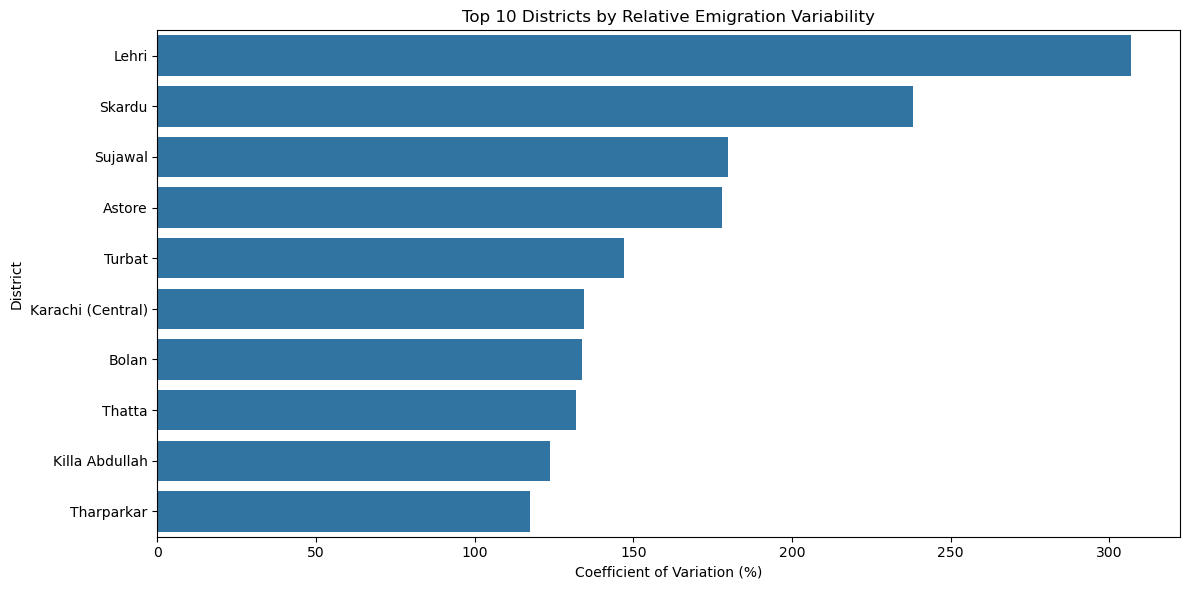

In [12]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=most_volatile,
    x='CV_Percent',
    y='Districts'
)

plt.title('Top 10 Districts by Relative Emigration Variability')
plt.xlabel('Coefficient of Variation (%)')
plt.ylabel('District')

plt.tight_layout()
plt.show()

### Compare district averages and variability

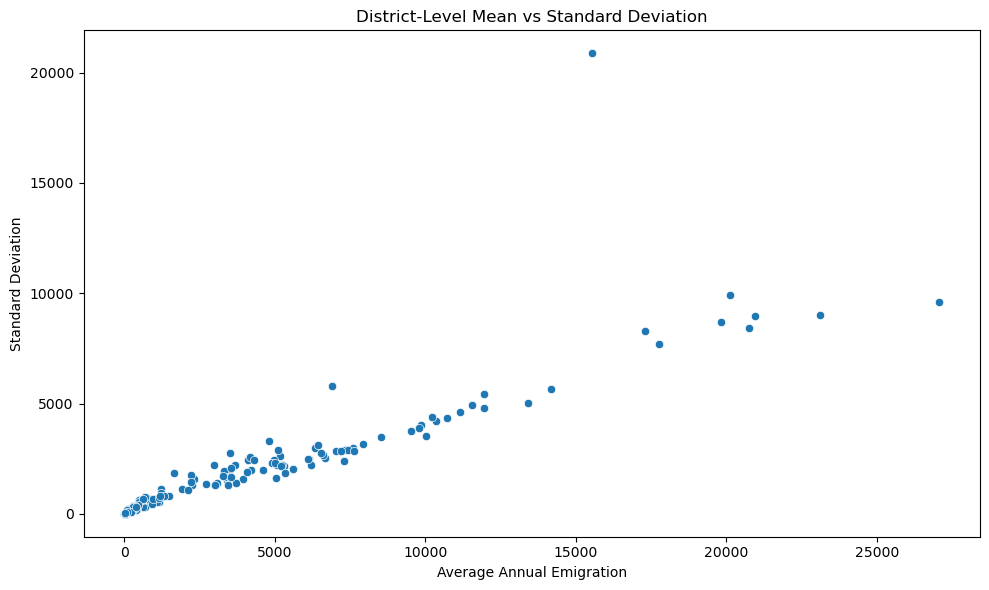

In [13]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=district_variability,
    x='Mean_Emigration',
    y='Std_Deviation'
)

plt.title('District-Level Mean vs Standard Deviation')
plt.xlabel('Average Annual Emigration')
plt.ylabel('Standard Deviation')

plt.tight_layout()
plt.show()

### Confidence Interval for the Mean

In [14]:
data = df['Historical_Total'].dropna()

n = len(data)
mean_value = data.mean()
std_error = stats.sem(data)

confidence_interval = stats.t.interval(
    confidence=0.95,
    df=n-1,
    loc=mean_value,
    scale=std_error
)

print("Mean:", mean_value)
print("95% Confidence Interval:", confidence_interval)

Mean: 50282.357142857145
95% Confidence Interval: (np.float64(40138.314363538404), np.float64(60426.399922175886))


### Annual Growth Statistics

In [15]:
annual_totals = df[years].sum()

growth = annual_totals.pct_change() * 100
growth = growth.dropna()

print("Mean Annual Growth:", round(growth.mean(), 2), "%")
print("Median Annual Growth:", round(growth.median(), 2), "%")
print("Growth Standard Deviation:", round(growth.std(), 2), "%")
print("Minimum Annual Growth:", round(growth.min(), 2), "%")
print("Maximum Annual Growth:", round(growth.max(), 2), "%")

Mean Annual Growth: 14.54 %
Median Annual Growth: 3.64 %
Growth Standard Deviation: 67.45 %
Minimum Annual Growth: -64.02 %
Maximum Annual Growth: 188.73 %


### Correlation Analysis

In [16]:
annual_totals = df[years].sum()


correlation_df = pd.DataFrame({
    'Year': annual_totals.index.astype(int),
    'Emigrants': annual_totals.values
})

from scipy.stats import pearsonr

correlation, p_value = pearsonr(
    correlation_df['Year'],
    correlation_df['Emigrants']
)

print("Pearson Correlation:", round(correlation, 4))
print("P-value:", round(p_value, 4))




Pearson Correlation: -0.0356
P-value: 0.9125


### Visualization

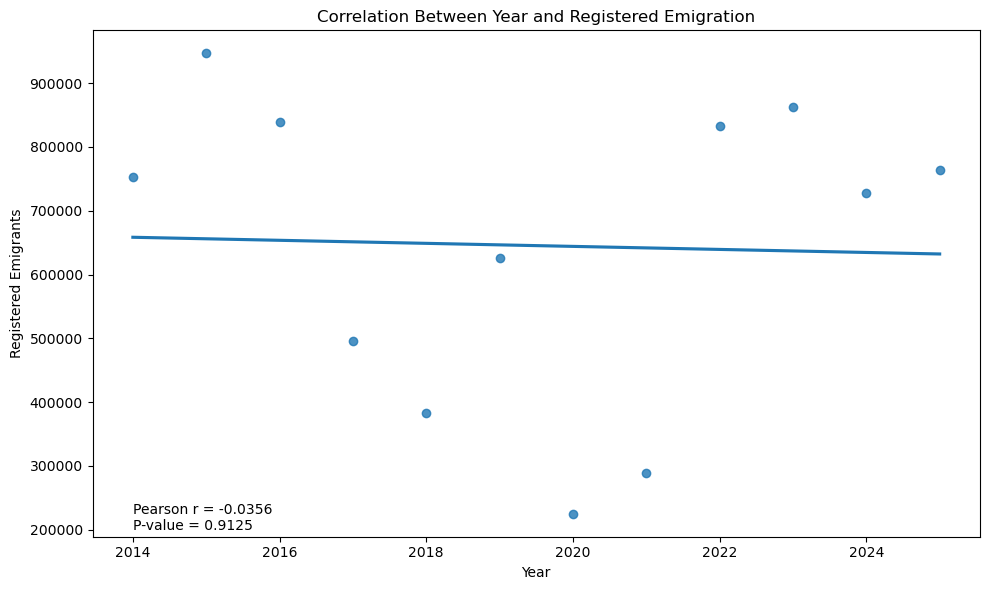

In [18]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=correlation_df,
    x='Year',
    y='Emigrants',
    ci=None
)

plt.title('Correlation Between Year and Registered Emigration')
plt.xlabel('Year')
plt.ylabel('Registered Emigrants')
plt.text(
    2014, 200000,
    f"Pearson r = {correlation:.4f}\n"
    f"P-value = {p_value:.4f}"
)

plt.tight_layout()
plt.show()

### COVID-19 Statistical Comparison

In [33]:
#Create period categories

def classify_period(year):
    if 2014 <= year <= 2019:
        return 'Pre-COVID'
    elif 2020 <= year <= 2021:
        return 'COVID'
    else:
        return 'Post-COVID'

correlation_df['Period'] = correlation_df['Year'].apply(classify_period)

correlation_df

,Year,Emigrants,Period
0,2014,752466,Pre-COVID
1,2015,946571,Pre-COVID
2,2016,839353,Pre-COVID
3,2017,496286,Pre-COVID
4,2018,382439,Pre-COVID
5,2019,625876,Pre-COVID
6,2020,225213,COVID
7,2021,288280,COVID
8,2022,832339,Post-COVID
9,2023,862625,Post-COVID


In [34]:
#Calculate descriptive statistics by period

period_summary = correlation_df.groupby('Period')['Emigrants'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max', 'sum']
).round(2)

period_summary

,count,mean,median,std,min,max,sum
Period,,,,,,,
COVID,2,256746.50,256746.5,44595.10,225213,288280,513493
Post-COVID,4,796749.75,797932.5,61554.21,728509,862625,3186999
Pre-COVID,6,673831.83,689171.0,212931.59,382439,946571,4042991


In [35]:
#Calculate percentage changes between periods

period_means = correlation_df.groupby('Period')['Emigrants'].mean()

pre_covid = period_means['Pre-COVID']
covid = period_means['COVID']
post_covid = period_means['Post-COVID']

covid_change = ((covid - pre_covid) / pre_covid) * 100
post_covid_change = ((post_covid - pre_covid) / pre_covid) * 100

print("COVID Period Change:", round(covid_change, 2), "%")
print("Post-COVID Change:", round(post_covid_change, 2), "%")

COVID Period Change: -61.9 %
Post-COVID Change: 18.24 %


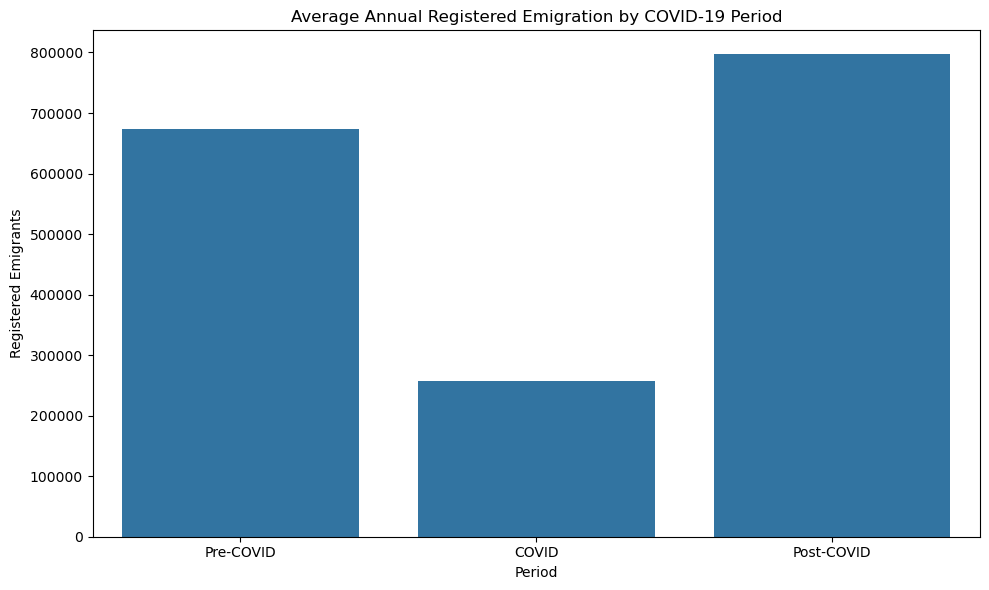

In [36]:
#Visualize the period comparison

plt.figure(figsize=(10, 6))

sns.barplot(
    data=correlation_df,
    x='Period',
    y='Emigrants',
    order=['Pre-COVID', 'COVID', 'Post-COVID'],
    errorbar=None
)

plt.title('Average Annual Registered Emigration by COVID-19 Period')
plt.xlabel('Period')
plt.ylabel('Registered Emigrants')

plt.tight_layout()
plt.show()

### Key Findings of Statistical Analysis
The statistical analysis examined district-level registered emigration in Pakistan from 2014 to 2025, focusing on descriptive statistics, distribution, dispersion, annual trends, and correlation.

1. Uneven distribution across districts: The mean historical emigration total per district was approximately 50,282, while the median was 27,344. The mean being considerably higher than the median indicates that a relatively small number of districts recorded substantially higher emigration totals.

2. High variation among districts: The standard deviation was approximately 63,720, with a minimum district total of 37 and a maximum of 324,939. This demonstrates considerable differences in registered emigration across districts.

3. Positive skewness: The skewness value of 1.918 indicates a positively skewed distribution. This suggests that most districts recorded comparatively lower totals, while a smaller number recorded substantially higher totals.

4. Heavy-tailed distribution: The kurtosis value of 3.925 (excess kurtosis) indicates a distribution with heavier tails than a normal distribution. This is consistent with the presence of districts having unusually high emigration totals.

5. Fluctuations in annual emigration: Annual registered emigration did not follow a consistent upward or downward pattern. The highest annual total was recorded in 2015 (946,571), while the lowest was recorded in 2020 (225,213).

6. Recovery after 2020: Registered emigration increased considerably after 2020, reaching 832,339 in 2022 and 862,625 in 2023. However, the figures subsequently declined in 2024 before increasing again in 2025.

7. Negligible linear correlation with time: The Pearson correlation coefficient between year and annual registered emigration was -0.0356, with a p-value of 0.9125. This indicates no statistically significant linear relationship between time and annual registered emigration during the study period.

8. Considerable geographical disparities: The descriptive statistics demonstrate that registered emigration was not evenly distributed across districts. Some districts contributed substantially more to the overall historical total than others.